Available laps: [np.int64(8), np.int64(9), np.int64(10), np.int64(11), np.int64(12), np.int64(13), np.int64(14), np.int64(15), np.int64(16), np.int64(17)]
[('accel_lat', <HDF5 dataset "accel_lat": shape (291333,), type "<f8">), ('accel_long', <HDF5 dataset "accel_long": shape (291333,), type "<f8">), ('accel_vert', <HDF5 dataset "accel_vert": shape (291333,), type "<f8">), ('brake', <HDF5 dataset "brake": shape (291333,), type "<f8">), ('clutch', <HDF5 dataset "clutch": shape (291333,), type "<f8">), ('fuel', <HDF5 dataset "fuel": shape (291333,), type "<f8">), ('gear', <HDF5 dataset "gear": shape (291333,), type "<i8">), ('lap_distance', <HDF5 dataset "lap_distance": shape (291333,), type "<f8">), ('lap_number', <HDF5 dataset "lap_number": shape (291333,), type "<i8">), ('lap_progress', <HDF5 dataset "lap_progress": shape (291333,), type "<f8">), ('orientation_yaw', <HDF5 dataset "orientation_yaw": shape (291333,), type "<f8">), ('position_x', <HDF5 dataset "position_x": shape (291333

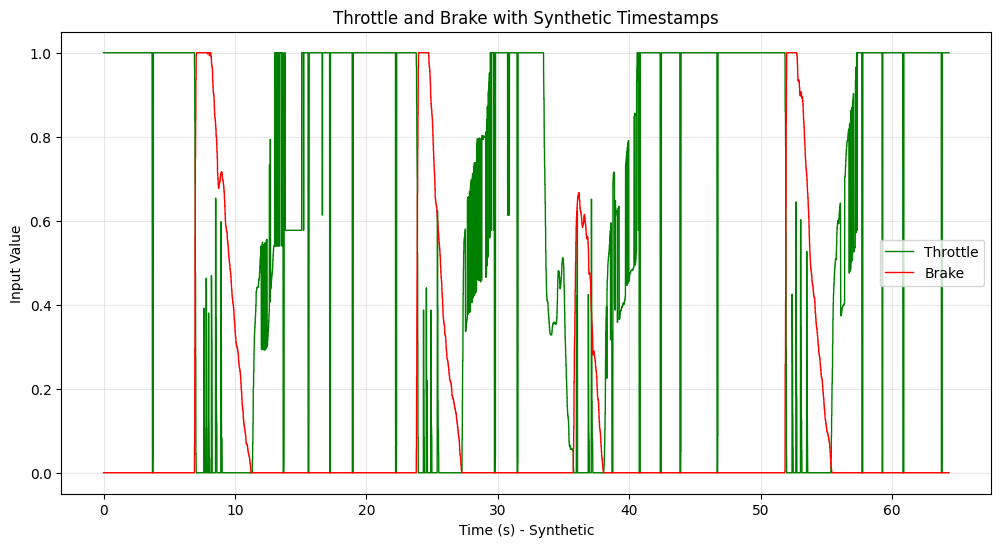

Total samples: 33627
Laptime: 64.343s
Sectortimes: [32.098, 13.398, 18.847]
Synthetic duration: 33.626s


In [34]:
import h5py
import numpy as np
import matplotlib.pyplot as plt
import os

def plot_throttle_brake(telemetry_file, lap_number=None):
    """
    Plot throttle and brake data from HDF5 telemetry file
    
    Args:
        telemetry_file: Path to the HDF5 telemetry file
        lap_number: Optional specific lap to plot
    """
    with h5py.File(telemetry_file, 'r') as f:
        # Access vehicle data
        vehicle_data = f['vehicle_data']
        
        # Get basic data
        timestamps = vehicle_data['session_time'][:]
        throttle = vehicle_data['throttle'][:]
        print(timestamps)
        brake = vehicle_data['brake'][:]
        lap_numbers = vehicle_data['lap_number'][:]
        
        # Filter by lap if specified
        if lap_number is not None:
            mask = lap_numbers == lap_number
            timestamps = timestamps[mask]
            throttle = throttle[mask]
            brake = brake[mask]
            
            # Check if we have data
            if len(timestamps) == 0:
                print(f"No data found for lap {lap_number}")
                return
            
            title = f"Throttle and Brake Telemetry - Lap {lap_number}"
        else:
            title = "Throttle and Brake Telemetry - Full Session"
        
        # Create plot
        plt.figure(figsize=(12, 6))
        
        # Plot throttle in green
        plt.plot(timestamps, throttle, 'g-', linewidth=2, label='Throttle')
        
        # Plot brake in red
        plt.plot(timestamps, brake, 'r-', linewidth=2, label='Brake')
        
        # Add labels and title
        plt.xlabel('Session Time (s)')
        plt.ylabel('Input Value')
        plt.title(title)
        plt.grid(True, alpha=0.3)
        plt.legend()
        
        # Set y-axis limits
        plt.ylim([-0.05, 1.05])
        
        plt.tight_layout()
        plt.show()

def plot_with_synthetic_timestamps(telemetry_file):
    with h5py.File(telemetry_file, 'r') as f:
        # Get vehicle data
        vehicle_data = f['telemetry_data']
        print(list(vehicle_data.items()))
        lap_mask = vehicle_data["lap_number"][:] == 15
        print(lap_mask.shape)
        sector_mask1 = vehicle_data["sector"][:][lap_mask] == 0
        sector_mask2 = vehicle_data["sector"][:][lap_mask] == 1
        sector_mask3 = vehicle_data["sector"][:][lap_mask] == 2        # Get the original timestamps and data
        timestamps = vehicle_data['timestamp'][:][lap_mask]#[sector_mask1]
        timestamps_sector1 = vehicle_data['timestamp'][:][lap_mask][sector_mask1]
        timestamps_sector2 = vehicle_data['timestamp'][:][lap_mask][sector_mask2]
        timestamps_sector3 = vehicle_data['timestamp'][:][lap_mask][sector_mask3]
        throttle = vehicle_data['throttle'][:][lap_mask]
        brake = vehicle_data['brake'][:][lap_mask]
        print(timestamps_sector3.shape)
        # Create synthetic timestamps (assuming 1ms intervals)
        sample_rate = 0.001  # 1ms
        num_samples = len(timestamps)
        synthetic_time = np.arange(0, num_samples * sample_rate, sample_rate)
        
        # Plot with synthetic timestamps
        plt.figure(figsize=(12, 6))
        plt.plot(timestamps-timestamps[0], throttle, 'g-', linewidth=1, label='Throttle')
        plt.plot(timestamps-timestamps[0], brake, 'r-', linewidth=1, label='Brake')
        
        plt.xlabel('Time (s) - Synthetic')
        plt.ylabel('Input Value')
        plt.title('Throttle and Brake with Synthetic Timestamps')
        plt.grid(True, alpha=0.3)
        plt.legend()
        
        plt.show()
        
        # You can also print some statistics
        print(f"Total samples: {num_samples}")
        print(f"Laptime: {timestamps[-1] - timestamps[0]:.3f}s")
        print(f"Sectortimes: [{timestamps_sector1[-1] - timestamps[0]:.3f}, {timestamps_sector2[-1]-timestamps_sector1[-1]:.3f}, {timestamps_sector3[-1]-timestamps_sector2[-1]:.3f}]")
        print(f"Synthetic duration: {synthetic_time[-1]:.3f}s")

def list_available_laps(telemetry_file):
    """List available laps in the telemetry file"""
    with h5py.File(telemetry_file, 'r') as f:
        if 'telemetry_data' in f and 'lap_number' in f['telemetry_data']:
            laps = np.unique(f['telemetry_data']['lap_number'][:])
            print(f"Available laps: {sorted(laps)}")
        else:
            print("No lap data found in file")

# Example usage:
if __name__ == "__main__":
    # Path to your telemetry file
    telemetry_path = r"C:\Users\szakt\OneDrive\Desktop\projects\RaceEngineer\VirtualSpotter\TinyPedal\tinypedal\logs\telemetry\20250303_110504_Bahrain Ou_Hyper - Pe_practice\telemetry.h5"
    
    # List available laps
    list_available_laps(telemetry_path)
    
    # Plot all data
    plot_with_synthetic_timestamps(telemetry_path)
    